# Stage 1: Descriptive Statistics

## Objective

Who are the players, how much do they spend, and is spending concentrated in a few people?

This stage (tracker tasks S1.1 to S1.4) describes the sample, checks which survey scales are reliable enough for Stages 2 to 4, and measures how unequal spending is with the Gini coefficient and the Lorenz curve. All tables and figures are written to `outputs/stage1/`.

In [20]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Output folders for Stage 1 (created if missing)
OUT = Path("../outputs/stage1")
FIG, TAB = OUT / "figures", OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

d = pd.read_csv("../Dataset/gacha_clean.csv", encoding="utf-8-sig")
print(d.shape)   # expected: (510, 52)

(510, 52)


## 1. Sample Description

Categorical variables (AGE, GAME, TENURE, STATUS) are summarised with counts and percentages only; a mean is not meaningful because the groups are not numbers.

In [21]:
# Natural display order for each variable (value_counts sorts by frequency by default)
thu_tu = {
    "AGE": ["18-22", "23-27", "28+"],
    "GAME": ["Genshin", "HSR", "WuWa", "ZZZ", "Other"],
    "TENURE": ["Less than 6 months", "6-12 months", "1-2 years", "More than 2 years"],
    "STATUS": ["Active, playing as usual", "Playing much less than before", "Quit in the last 6 months"],
}

for col, order in thu_tu.items():
    n = d[col].value_counts().reindex(order)                           # respondents per group
    pct = (d[col].value_counts(normalize=True) * 100).reindex(order)   # % per group
    bang = pd.DataFrame({"n": n, "%": pct.round(1)})
    print(f"--- {col} ---")
    print(bang, "\n")

--- AGE ---
         n     %
AGE             
18-22  409  80.2
23-27   78  15.3
28+     23   4.5 

--- GAME ---
           n     %
GAME              
Genshin  151  29.6
HSR       81  15.9
WuWa      26   5.1
ZZZ      219  42.9
Other     33   6.5 

--- TENURE ---
                      n     %
TENURE                       
Less than 6 months   35   6.9
6-12 months          35   6.9
1-2 years           137  26.9
More than 2 years   303  59.4 

--- STATUS ---
                                 n     %
STATUS                                  
Active, playing as usual       382  74.9
Playing much less than before  111  21.8
Quit in the last 6 months       17   3.3 



In [22]:
# PAYER = has ever spent, PAYER_NOW = spends monthly (0/1)
for col in ["PAYER", "PAYER_NOW"]:
    n = d[col].value_counts()
    pct = d[col].value_counts(normalize=True) * 100
    bang = pd.DataFrame({"n": n, "%": pct.round(1)})
    print(f"--- {col} ---")
    print(bang, "\n")

--- PAYER ---
         n     %
PAYER           
1      356  69.8
0      154  30.2 

--- PAYER_NOW ---
             n     %
PAYER_NOW           
1          292  57.3
0          218  42.7 



In [23]:
# Combine the sample profile into one CSV table for the report
rows = []
for col, order in thu_tu.items():
    n = d[col].value_counts().reindex(order)
    for g in order:
        rows.append([col, g, int(n[g]), round(n[g] / len(d) * 100, 1)])
for col, label in [("PAYER", "Has ever spent"), ("PAYER_NOW", "Spends monthly")]:
    rows.append([col, label, int(d[col].sum()), round(d[col].mean() * 100, 1)])   # the mean of a 0/1 column is a proportion
sample_tbl = pd.DataFrame(rows, columns=["Variable", "Group", "n", "%"])
sample_tbl.to_csv(TAB / "stage1_sample_profile.csv", index=False, encoding="utf-8-sig")
sample_tbl

,Variable,Group,n,%
0,AGE,18-22,409,80.2
1,AGE,23-27,78,15.3
2,AGE,28+,23,4.5
3,GAME,Genshin,151,29.6
4,GAME,HSR,81,15.9
5,GAME,WuWa,26,5.1
6,GAME,ZZZ,219,42.9
7,GAME,Other,33,6.5
8,TENURE,Less than 6 months,35,6.9
9,TENURE,6-12 months,35,6.9


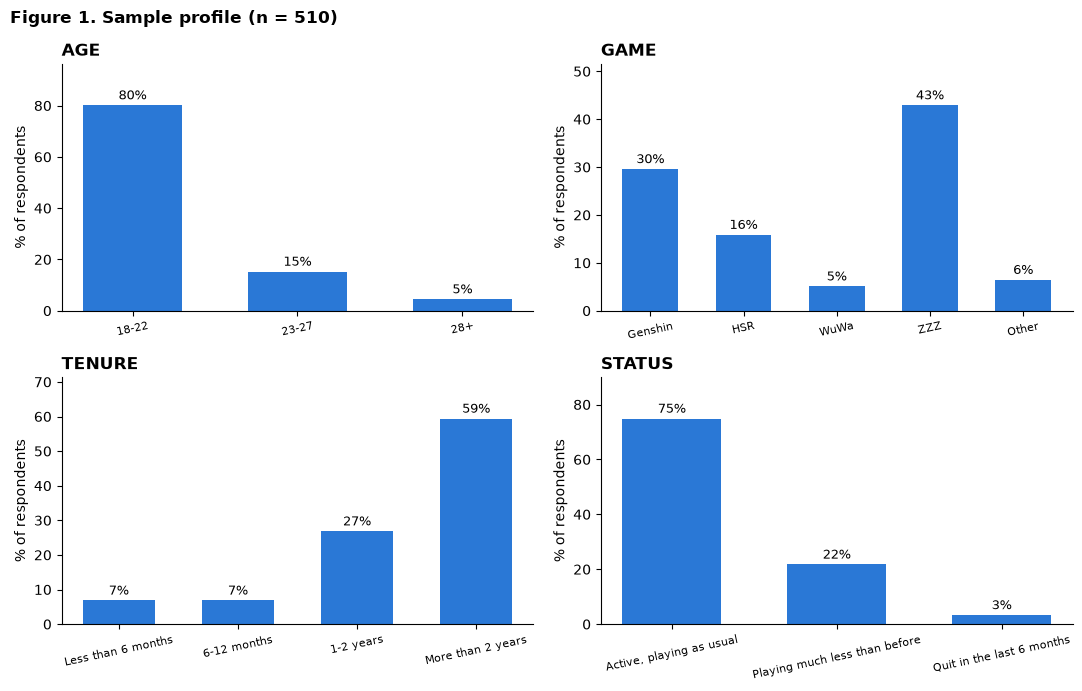

In [24]:
# Bar charts: 4 variables in one figure (2 rows x 2 columns)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (col, order) in zip(axes.flat, thu_tu.items()):
    pct = d[col].value_counts(normalize=True).reindex(order) * 100
    bars = ax.bar(order, pct, color="#2a78d6", width=0.6)
    ax.bar_label(bars, labels=[f"{p:.0f}%" for p in pct], padding=2, fontsize=9)   # % label on each bar
    ax.set_title(col, loc="left", fontweight="bold")
    ax.set_ylabel("% of respondents")
    ax.set_ylim(0, pct.max() * 1.2)
    ax.tick_params(axis="x", labelsize=8, rotation=12)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Figure 1. Sample profile (n = {len(d)})", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "sample_profile.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Scale reliability (Cronbach's alpha)

Each construct is measured by several 1–5 Likert items. Cronbach's alpha shows whether the items of one scale move together, that is, whether they measure the same thing. The usual threshold is 0.70.

$$\alpha = \frac{k}{k-1}\left(1 - \frac{\sum_{i=1}^{k} s_i^2}{s_T^2}\right)$$

$k$ is the number of items, $s_i^2$ the variance of item $i$ and $s_T^2$ the variance of the total score. Alpha rises with the number of items, so for two-item scales we also report the correlation between the two items.

In [25]:
def cronbach_alpha(X):
    k = X.shape[1]                              # number of items in the scale
    item_var = X.var(ddof=1).sum()              # sum of item variances
    total_var = X.sum(axis=1).var(ddof=1)       # variance of the total score
    return k / (k - 1) * (1 - item_var / total_var)

scales = {
    "LUCK":  ["Q13", "Q14", "Q15"],
    "PITY":  ["Q16", "Q17", "Q18"],
    "PRICE": ["Q19", "Q20", "Q21"],
    "SAT":   ["Q22", "Q23", "Q24"],
    "INT":   ["Q25", "Q26", "Q27"],
    "RET":   ["Q28", "Q29", "Q30"],
    "PITY2": ["Q17", "Q18"],     # Q16 dropped because PITY failed
    "SAT2":  ["Q22", "Q23"],     # used for the Stage 4 sensitivity check
}
rows = []
for name, items in scales.items():
    a = cronbach_alpha(d[items])
    r = d[items[0]].corr(d[items[1]]) if len(items) == 2 else np.nan   # inter-item correlation
    rows.append([name, "–".join([items[0], items[-1]]), len(items), round(a, 3),
                 round(r, 2) if len(items) == 2 else None, "Yes" if a >= 0.70 else "No"])
alpha_tbl = pd.DataFrame(rows, columns=["Scale", "Items", "k", "Alpha", "Inter-item r", "Alpha ≥ 0.70"])
alpha_tbl.to_csv(TAB / "stage1_cronbach_alpha.csv", index=False, encoding="utf-8-sig")
alpha_tbl

,Scale,Items,k,Alpha,Inter-item r,Alpha ≥ 0.70
0,LUCK,Q13–Q15,3,0.821,NaN,Yes
1,PITY,Q16–Q18,3,0.540,NaN,No
2,PRICE,Q19–Q21,3,0.701,NaN,Yes
3,SAT,Q22–Q24,3,0.815,NaN,Yes
4,INT,Q25–Q27,3,0.818,NaN,Yes
5,RET,Q28–Q30,3,0.481,NaN,No
6,PITY2,Q17–Q18,2,0.610,0.44,No
7,SAT2,Q22–Q23,2,0.831,0.71,Yes


LUCK, PRICE, SAT and INT pass the 0.70 threshold. PITY and RET do not, so later stages use PITY2 (Q17–18) and RET1 (Q28 only). PITY2 is still below 0.70; with only two items alpha is naturally low, and the inter-item correlation is reported as additional evidence. This is noted as a limitation. RET1 is a single item, so alpha does not apply.

## 3. Scale scores

Each score is the mean of its items (1 = strongly disagree, 5 = strongly agree). Because the items are ordinal, we report the median and the distribution alongside the mean.

In [26]:
score_cols = ["LUCK", "PITY2", "PRICE", "SAT", "RET1"]
score_tbl = d[score_cols].agg(["count", "mean", "std", "median", "min", "max"]).T.round(2)
score_tbl.to_csv(TAB / "stage1_scale_scores.csv", encoding="utf-8-sig")
score_tbl

,count,mean,std,median,min,max
LUCK,510.0,3.17,0.99,3.33,1.0,5.0
PITY2,510.0,3.35,1.01,3.50,1.0,5.0
PRICE,510.0,3.12,0.90,3.00,1.0,5.0
SAT,510.0,4.10,0.86,4.33,1.0,5.0
RET1,510.0,4.45,1.01,5.00,1.0,5.0


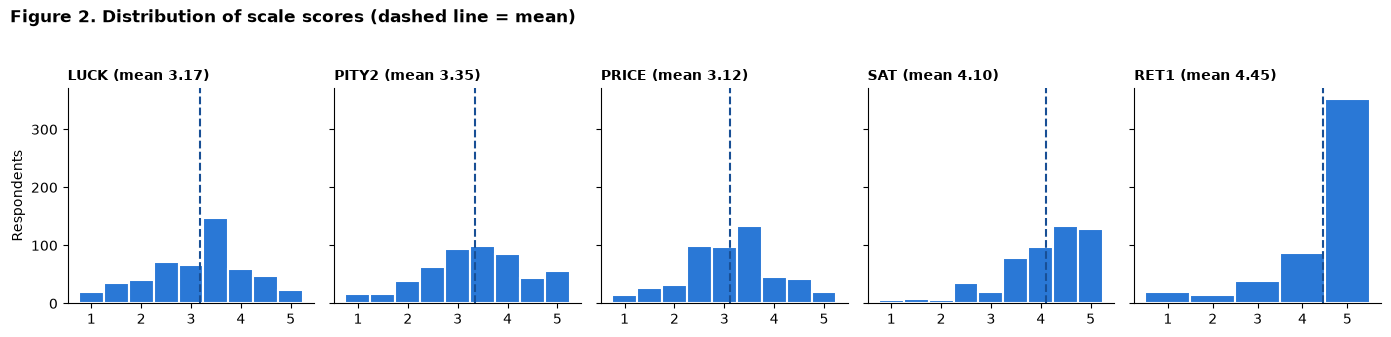

In [27]:
# Histograms for the 5 scales; dashed line = mean
fig, axes = plt.subplots(1, 5, figsize=(14, 3.2), sharey=True)
for ax, col in zip(axes, score_cols):
    bins = np.arange(0.5, 5.6, 1) if col == "RET1" else np.arange(0.75, 5.5, 0.5)   # RET1 is a single item, so scores are integers
    ax.hist(d[col], bins=bins, color="#2a78d6", edgecolor="white", linewidth=1.5)
    ax.axvline(d[col].mean(), color="#184f95", linestyle="--", linewidth=1.5)
    ax.set_title(f"{col} (mean {d[col].mean():.2f})", loc="left", fontsize=10, fontweight="bold")
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Respondents")
fig.suptitle("Figure 2. Distribution of scale scores (dashed line = mean)", x=0.01, ha="left", fontweight="bold", y=1.04)
fig.tight_layout()
fig.savefig(FIG / "scale_scores.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Spending concentration (Gini coefficient and Lorenz curve)

Q6 asks for lifetime spending in bands, so each respondent gets the midpoint of their band (`SPEND_TOTAL_VND_MID`). The top band has no upper limit, so we run three assumptions for it (20M, 25M and 40M VND) and report the range. This is a sensitivity check.

With spending sorted in ascending order $x_1 \le \dots \le x_n$:

$$G = \frac{2\sum_{i=1}^{n} i\,x_i}{n\sum_{i=1}^{n} x_i} - \frac{n+1}{n}$$

$G = 0$ means everyone spends the same; $G = 1$ means one person spends everything. The Lorenz curve plots the cumulative share of respondents (sorted from lowest to highest spender) against their cumulative share of total spending. We use all 510 respondents, including non-spenders, because the question is how spending is spread across all players.

In [28]:
print(d.groupby("SPEND_TOTAL")["SPEND_TOTAL_VND_MID"].agg(["size", "first"]))   # respondents and midpoint per band

def gini(x):
    x = np.sort(np.asarray(x, dtype=float))     # sort ascending
    n = len(x)
    i = np.arange(1, n + 1)                     # ranks 1..n
    return 2 * np.sum(i * x) / (n * x.sum()) - (n + 1) / n

def top_share(x, p):
    x = np.sort(np.asarray(x, dtype=float))[::-1]   # sort descending
    k = int(np.ceil(p * len(x)))                    # number of respondents in the top p
    return x[:k].sum() / x.sum()

TOP_BAND = d["SPEND_TOTAL"].max()
def spend_with_top(top_value):
    # replace the top band's value with the assumed top_value
    return d["SPEND_TOTAL_VND_MID"].where(d["SPEND_TOTAL"] != TOP_BAND, top_value)

rows = []
for top in [20e6, 25e6, 40e6]:
    x = spend_with_top(top)
    rows.append([f"{top/1e6:.0f}M", round(gini(x), 3), round(gini(x[x > 0]), 3),
                 round(top_share(x, 0.10) * 100, 1), round(top_share(x, 0.20) * 100, 1)])
gini_tbl = pd.DataFrame(rows, columns=["Top band", "Gini (all)", "Gini (spenders only)", "Top 10% share (%)", "Top 20% share (%)"])
gini_tbl.to_csv(TAB / "stage1_gini.csv", index=False, encoding="utf-8-sig")
gini_tbl

             size       first
SPEND_TOTAL                  
0.0           154         0.0
1.0           105    250000.0
2.0           119   1250000.0
3.0            64   3500000.0
4.0            44  10000000.0
5.0            24  25000000.0


,Top band,Gini (all),Gini (spenders only),Top 10% share (%),Top 20% share (%)
0,20M,0.748,0.639,56.9,78.8
1,25M,0.765,0.663,60.5,80.5
2,40M,0.802,0.717,68.4,84.4


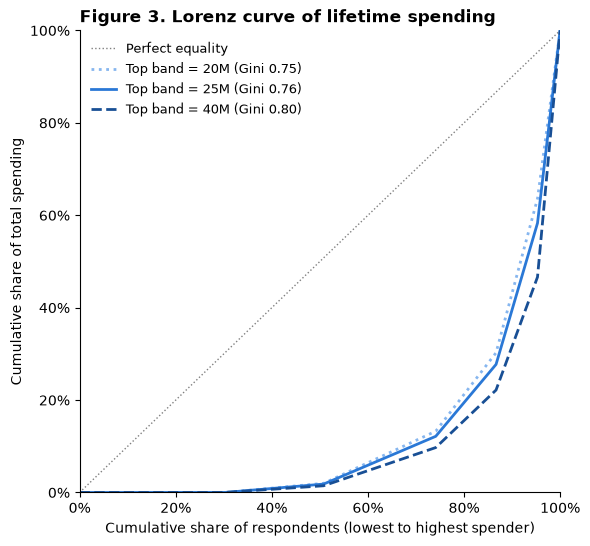

In [29]:
fig, ax = plt.subplots(figsize=(6.2, 6))
ax.plot([0, 1], [0, 1], color="grey", linewidth=1, linestyle=":", label="Perfect equality")
styles = {20e6: (":", "#86b6ef"), 25e6: ("-", "#2a78d6"), 40e6: ("--", "#184f95")}
for top, (ls, color) in styles.items():
    x = np.sort(spend_with_top(top).values)
    L = np.insert(np.cumsum(x) / x.sum(), 0, 0)     # cumulative share of spending
    P = np.linspace(0, 1, len(L))                   # cumulative share of respondents
    ax.plot(P, L, ls, color=color, linewidth=2, label=f"Top band = {top/1e6:.0f}M (Gini {gini(x):.2f})")
ax.set_xlabel("Cumulative share of respondents (lowest to highest spender)")
ax.set_ylabel("Cumulative share of total spending")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Figure 3. Lorenz curve of lifetime spending", loc="left", fontweight="bold")
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.savefig(FIG / "lorenz_curve.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Answer to the Stage 1 question

The summary below is computed from the tables above, so it updates if the data change.

In [30]:
age = d["AGE"].value_counts(normalize=True) * 100
game = d["GAME"].value_counts(normalize=True) * 100
g = gini_tbl["Gini (all)"]; t10 = gini_tbl["Top 10% share (%)"]
print(f"- {len(d)} respondents; {age.idxmax()} is the largest age group ({age.max():.1f}%), "
      f"and {game.idxmax()} is the most played game ({game.max():.1f}%).")
print(f"- {d['PAYER'].mean()*100:.1f}% have ever spent money; {d['PAYER_NOW'].mean()*100:.1f}% spend monthly.")
print(f"- Spending is highly concentrated: Gini {g.min():.2f}–{g.max():.2f} depending on the top-band assumption; "
      f"the top 10% of spenders account for {t10.min():.0f}–{t10.max():.0f}% of all spending.")
print("- Scales used in later stages: LUCK, PRICE, SAT (alpha ≥ 0.70); PITY2 and RET1 replace PITY and RET.")

- 510 respondents; 18-22 is the largest age group (80.2%), and ZZZ is the most played game (42.9%).
- 69.8% have ever spent money; 57.3% spend monthly.
- Spending is highly concentrated: Gini 0.75–0.80 depending on the top-band assumption; the top 10% of spenders account for 57–68% of all spending.
- Scales used in later stages: LUCK, PRICE, SAT (alpha ≥ 0.70); PITY2 and RET1 replace PITY and RET.


**Notes for the report**

- Write "is associated with", not "causes": the survey is a one-time snapshot.
- The sample is not random (recruited from online communities), so figures describe respondents, not all gacha players.
- Gini uses band midpoints, so it is an estimate; spending differences within a band are ignored, so the true Gini may be higher.